# Matched Filtering: Finding Signals in Noise

Problems IVa and IVb of [DSFP Session 27](https://github.com/LSSTC-DSFP/Session-27).

Rough timeline:

* **IVa (10:00)**: Problems 1 and 2.  Problem 3 if time allows.
* **IVb (11:00)**: Problem 4.  Problem 3 if time didn't allow.  Bonus problem.

* * *

By Luke Bouma (Caltech/IPAC)

## Learning Goals

By the end of this notebook, you will be able to:
1. Use `numpy` to implement a matched filter as a weighted linear fit
2. Measure the distribution of a detection statistic with noise alone, and with
   a signal present.
3. Extend one template to a template bank, and choose its spacing
4. Set a threshold from a trials argument and from an empirical null,
   and explain why they differ
5. Measure detection efficiency by injection and recovery
6. Search a few thousand light curves for a signal that has no
   template

## Problems

* [Problem 1) One pulse in white noise](#Problem-1\)-One-pulse-in-white-noise)
* [Problem 2) Transits: a periodic template](#Problem-2\)-Transits:-a-periodic-template)
* [Problem 3) Microlensing: aperiodic, gappy, blended](#Problem-3\)-Microlensing:-aperiodic,-gappy,-blended)
* [Problem 4) No template](#Problem-4\)-No-template)
* [Challenge Problem) Trigger on a rising event](#Challenge-Problem\)-Trigger-on-a-rising-event)

*Recap:* we discussed the scenario where the data are an amplitude $A$ times a
   template $s$, plus noise $n$,

$$d = A\,s + n, \qquad n \sim \mathcal{N}(0, C),$$

and detection asks whether $A$ differs from zero. The least-squares
solution is

$$\hat{A} = \frac{s^T C^{-1} d}{s^T C^{-1} s}, \qquad
\sigma_A = \frac{1}{\sqrt{s^T C^{-1} s}}, \qquad
\mathrm{SNR} = \frac{\hat{A}}{\sigma_A},$$

where for independent noise $C$ is diagonal, $C_{ii} = \sigma_i^2$, and the
matrix products become sums over $s_i d_i / \sigma_i^2$ and
$s_i^2 / \sigma_i^2$.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from astropy.timeseries import BoxLeastSquares, LombScargle

import mf_helpers as mf

# interactive plots require ipympl:
# pip install ipympl if you don't have it
%matplotlib ipympl
plt.rcParams["figure.max_open_warning"] = 0

`mf_helpers.py` contains simulators and loaders for fake and real data,
   respectively.  They use fixed seeds, so everyone's numbers should
   match.

## Problem 1) One pulse in white noise

Let's consider the case of one template, with known shape, known arrival time,
and white noise of known amplitude.

In [20]:
# execute this cell
t, d, sigma = mf.make_pulse_data()
s = mf.pulse_template(t)

print(f"{t.size} samples, noise sigma = {sigma}")

1000 samples, noise sigma = 1.0


**Problem 1a**

Plot the data `d` against `t`. A Gaussian pulse with the shape of the
template `s` is in there, with an expected SNR of 5. Can you see it?
Overplot the template once you have looked.

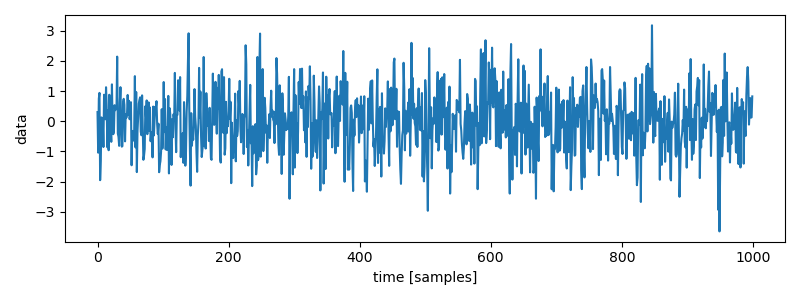

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, d)
# complete
ax.set_xlabel("time [samples]")
ax.set_ylabel("data")
fig.tight_layout()

**Problem 1b**

Write `matched_filter(d, s, sigma)`, which returns $\hat{A}$,
$\sigma_A$, and the SNR for independent noise.  Once you've written it, apply
it to the data.

*Note* - here `d` is one data set, with shape `(n_samples,)`. From Problem 1c
   on we will pass the same function thousands of data sets at once, so `d`
   will become a 2-D array with one data set per row, shape `(n_realizations, n_samples)`.
   We want our function to return one $\hat{A}$ and one SNR per row.  Run the
   cell after this one to test your implementation.

<details>
<summary><em>Hint</em> (click to show)</summary>

Consider `np.sum(..., axis=-1)`.

</details>

In [11]:
C_inv = np.diag(np.array([1 / sigma**2]))
a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
sigma_a = 1 / np.sqrt(s.T @ C_inv @ s)
snr = a_hat / sigma_a

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 1 is different from 1000)

In [34]:
s.T.shape

(1000, 1)

In [35]:
s = np.atleast_2d(s)
d = np.atleast_2d(d)
# w = # complete
C_inv = np.diag(np.array([1 / sigma**2]))
a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
sigma_a = 1 / np.sqrt(s.T @ C_inv @ s)
snr = a_hat / sigma_a

/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/805131554.py:5: RuntimeWarning: divide by zero encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/805131554.py:5: RuntimeWarning: overflow encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/805131554.py:5: RuntimeWarning: invalid value encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/805131554.py:6: RuntimeWarning: divide by zero encountered in divide
  sigma_a = 1 / np.sqrt(s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/805131554.py:7: RuntimeWarning: invalid value encountered in divide
  snr = a_hat / sigma_a


In [41]:
s.T.shape, C_inv.shape, d.shape

((1000, 1), (1, 1), (1, 1000))

In [14]:
def matched_filter(d, s, sigma):
    '''Fit the amplitude of template s to data d.

    Args:
        d: Data, shape (n,) or (m, n).
        s: Template, shape (n,).
        sigma: Noise standard deviation, scalar or shape (n,).

    Returns:
        Tuple (a_hat, sigma_a, snr).
    '''
    s = np.atleast_2d(s)
    d = np.atleast_2d(d)
    # w = # complete
    C_inv = np.diag(np.array([1 / sigma**2]))
    a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
    sigma_a = 1 / np.sqrt(s.T @ C_inv @ s)
    snr = a_hat / sigma_a
    return a_hat, sigma_a, snr


a_hat, sigma_a, snr = matched_filter(d, s, sigma)
print(f"A = {a_hat:.3f} +/- {sigma_a:.3f}, SNR = {snr:.2f}")

/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/1011436886.py:16: RuntimeWarning: divide by zero encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/1011436886.py:16: RuntimeWarning: overflow encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/1011436886.py:16: RuntimeWarning: invalid value encountered in divide
  a_hat = s.T @ C_inv @ d / (s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/1011436886.py:17: RuntimeWarning: divide by zero encountered in divide
  sigma_a = 1 / np.sqrt(s.T @ C_inv @ s)
/var/folders/hp/s_nzb6m11p71g75pyb28wjtr0000gn/T/ipykernel_23764/1011436886.py:18: RuntimeWarning: invalid value encountered in divide
  snr = a_hat / sigma_a


TypeError: unsupported format string passed to numpy.ndarray.__format__

In [ ]:
# execute this cell to test your matched_filter

# noise-free data that are exactly 3 times the template
a_test, sigma_test, _ = matched_filter(3 * s, s, sigma)
assert np.isclose(a_test, 3), f"expected A = 3, got {a_test}"
assert np.isclose(sigma_test, sigma / np.sqrt(np.sum(s**2)))

# a stack of three data sets, one per row
stack = np.vstack([d, 2 * d, np.zeros_like(d)])
snr_stack = matched_filter(stack, s, sigma)[2]
assert np.shape(snr_stack) == (3,), (
    f"expected one SNR per row, got shape {np.shape(snr_stack)}: "
    "sum over axis=-1")
assert np.allclose(snr_stack, [snr, 2 * snr, 0])
print("matched_filter passes")

**Problem 1c**

Alright!  You now have a detection.  Or do you?
This SNR measurement doesn't mean much without knowing what distribution it
came from.  Also, we haven't set our threshold for what a detection means!

Your first task: draw $10^4$ noise-only data sets, matched filter each one with
the same template, and plot up a histogram of the SNRs.   This is your null
distribution.  Compare it to the standard gaussian $\mathcal{N}(0, 1)$.

In [ ]:
rng = np.random.default_rng(1)
noise = # complete; noise should have shape (10000,1000)
snr_null = # complete

x = np.linspace(-5, 10, 500)
bins = np.linspace(-5, 10, 76)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(  # complete
ax.plot(  # complete
ax.set_xlabel("SNR")
ax.legend()
fig.tight_layout()
print(f"mean = {snr_null.mean():.3f}, std = {snr_null.std():.3f}")

**Problem 1d**

Good.  Now, let's build the distribution of the detection statistic when a
signal is present, the "signal distribution" counterpart to 1c.  Do this by
injecting a pulse into every noise realization, at the amplitude that gives an
expected SNR of 5.  Overplot the histograms of the null and signal
distributions. Then define a threshold for detection, for instance 3 sigma, and
read off the detection efficiency (fraction of signals above threshold) and the
false alarm probability (fraction of noise-only data sets above threshold).

In [ ]:
amp = # complete
d_inj = # complete
snr_sig = # complete

threshold = # complete
efficiency = # complete
false_alarm = # complete

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(snr_null, bins=bins, density=True, alpha=0.5, label="noise")
# complete
ax.axvline(threshold, c="C3")
ax.set_xlabel("SNR")
ax.legend()
fig.tight_layout()
print(f"threshold {threshold}: efficiency = {efficiency:.3f}, "
      f"false alarm probability = {false_alarm:.4f}")
print(f"Gaussian prediction: {stats.norm.sf(threshold - 5):.3f}, "
      f"{stats.norm.sf(threshold):.4f}")

**Problem 1e**

So far we've assumed that we know when the pulse arrives.
(In 1a–1d the template is `s = mf.pulse_template(t)`, which is centered at `t0 =
 600`, and `mf.make_pulse_data()` injects the pulse at that same `t0 = 600`.)
Let's relax this assumption, and suppose we do not know when the pulse arrives.
Our goal is now to slide the template: compute the SNR for a pulse centered on
every sample, and plot SNR against trial arrival time `t0` for the data from
1a.

(Note that we are still assuming a fixed pulse width of 10 samples, and a
gaussian shape...)

In [ ]:
def sliding_snr(d, t, sigma):
    '''Matched-filter SNR for a pulse centered on each sample in turn.

    Args:
        d: Data, shape (n,) for one data set or (m, n) for a stack of
            m data sets.
        t: Sample times, shape (n,). Each one is used as a trial
            arrival time t0.
        sigma: Noise standard deviation, scalar or shape (n,).

    Returns:
        SNR at each trial t0: shape (n,) for one data set, or (n, m)
        for a stack, with one row per trial t0 and one column per
        data set.
    '''
    snr = []
    for t0 in t:
        # get the pulse template at t0...
        # and build the SNR at each t0
    return # complete


snr_t0 = sliding_snr(d, t, sigma)

fig, ax = plt.subplots(figsize=(8, 3))
# complete
ax.set_xlabel("trial arrival time t0 [samples]")
ax.set_ylabel("SNR")
fig.tight_layout()
print(f"max SNR = {snr_t0.max():.2f} at t0 = {t[np.argmax(snr_t0)]:.0f}")

The detection statistic is now the *maximum* SNR over `t0`. What is
its null distribution? Run the sliding filter on 1000 of your
noise-only data sets, keep the maximum of each, and compare against the null
distribution you saw in 1c.
What threshold gives a 1% false alarm probability now, and what did it take in
1c?

In [ ]:
# rows are trial t0, columns are data sets: take the maximum over t0
max_null = # complete

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(snr_null, bins=bins, density=True, alpha=0.5,
        label="t0 known")
ax.hist(  # complete
ax.plot(x, stats.norm.pdf(x), c="k")
ax.set_xlabel("SNR")
ax.legend()
fig.tight_layout()

thr_one = # complete
thr_max = # complete
n_eff = np.log(2) / stats.norm.sf(np.median(max_null))
print(f"1% false alarm threshold: {thr_one:.2f} (one template), "
      f"{thr_max:.2f} (max over t0)")
print(f"effective number of independent templates: {n_eff:.0f}")

The last line of that cell inverts the median of the maximum of $N$
independent standard normal draws, to estimate how many *independent* templates
the 1000 trial arrival times amount to.

Why is that number so much smaller than 1000?

*Provide your answer to Problem 1e here*

## Problem 2) Transits: a periodic template

In Problem 1 we had one pulse, and we searched over its arrival time.  Transit
searches look for a box signal once per orbitral period.  These searches have
three nonlinear parameters (period $P$, epoch $t_0$, and duration) and two
linear ones (depth and baseline).   In the box least squares (BLS) algorithm
([Kovács et al. 2002](https://scixplorer.org/abs/2002A%26A...391..369K/abstract)), just
like in the earlier problem, we solve for the linear parameters with the
matched filter, and grid over the nonlinear ones.

(Note that we are assuming a transit is a box: flat-bottomed, with instant
 ingress and egress.  Real transits have limb darkening, so a box template
 loses a little SNR relative to the optimal shape.)

In [ ]:
# execute this cell
t, flux, ferr = mf.make_transit_lc()

print(f"{t.size} points over {t.max() - t.min():.1f} d, "
      f"per-point error = {ferr[0] * 1e6:.0f} ppm")

**Problem 2a**

Plot the light curve.  It covers 27 days at 30 minute cadence, like
one TESS sector, and it contains an injected planet.  Can you see it?

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
# complete
ax.set_xlabel("time [d]")
ax.set_ylabel("relative flux")
fig.tight_layout()

**Problem 2b**

Let's start as we did in Problem 1, with one template whose parameters
we already know.  The injected planet has $P = 3.7$ d, $t_0 = 1.3$ d,
and a duration of $0.125$ d.

Our model for the flux is a constant baseline $b$, minus a box of
depth $\delta$,

$$f_i = b - \delta\,\mathrm{box}_i + n_i,$$

where $\mathrm{box}_i$ is 1 for points in transit and 0 for points out of
transit.  The function `mf.box_model(t, period, t0, duration)` implements the
box function (`True` in transit).

Compare this to $d = A\,s + n$ from Problem 1: the amplitude $A$ is the depth
$\delta$, and the template $s$ is $-\mathrm{box}$, which is $-1$ in transit and
$0$ out of transit.

The one new ingredient is the baseline $b$: the out-of-transit flux level,
which is a linear nuisance parameter.  In general that means a two-column fit
and marginalization over it, which we'll do in Problem 3.   However, in this
particular model there is a shortcut: with equal error bars you can remove it by
subtracting the mean from both the data and the template.  (After that
subtraction the template is no longer 0 and $-1$.  With 3% of the points in
transit, it is about $-0.97$ in transit and $+0.03$ out of transit.)

Complete `box_snr`, which builds this template and uses your
`matched_filter` from Problem 1 to measure the depth and its SNR.

Then complete `fold`, which converts times to time from the nearest
mid-transit, and plot the folded light curve.  This cell completes one BLS
evaluation.

(Run the cell after this one to test both functions, since we reuse them in 2c
and 2d.)

In [ ]:
def box_snr(t, flux, ferr, period, t0, duration):
    '''Fit the depth of one box-shaped transit template.

    Args:
        t: Times in days, shape (n,).
        flux: Relative flux, shape (n,).
        ferr: Flux uncertainties, shape (n,), all equal.
        period: Trial period in days.
        t0: Trial mid-transit time in days.
        duration: Trial transit duration in days.

    Returns:
        Tuple (depth, depth_err, snr). The depth is positive for a
        dip.
    '''
    # True (1) for points in transit, False (0) for points out of transit
    in_transit = mf.box_model(t, period, t0, duration)
    # template for a dip of unit depth: -1 in transit, 0 out of transit
    box = # complete
    # remove the baseline: subtract the mean from the template and the data
    s = # complete
    d = # complete
    # the fitted amplitude is the transit depth
    return # complete


def fold(t, period, t0):
    '''Time from the nearest mid-transit.

    Args:
        t: Times in days.
        period: Period in days.
        t0: Mid-transit time in days.

    Returns:
        Times in days, between -period / 2 and +period / 2, with
        zero at mid-transit.
    '''
    # complete (this can take a few lines)


# the injected planet
p_true, t0_true, dur_true = 3.7, 1.3, 0.125

depth, depth_err, snr = # complete
print(f"depth = {depth * 1e6:.0f} +/- {depth_err * 1e6:.0f} ppm, "
      f"SNR = {snr:.2f}")

phase = # complete
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(phase, flux, "k.", ms=2)
ax.set_xlabel("time from mid-transit [d]")
ax.set_ylabel("relative flux")
ax.set_xlim(-1, 1)
fig.tight_layout()

In [ ]:
# execute this cell to test your box_snr and fold

# a noise-free light curve with one 1000 ppm box
flux_test = mf.inject_transit(t, np.ones_like(t), p_true, t0_true,
                              dur_true, 1e-3)
depth_test = box_snr(t, flux_test, ferr, p_true, t0_true, dur_true)[0]
assert np.isclose(depth_test, 1e-3), (
    f"expected a depth of 0.001, got {depth_test}")

# a brightening is a negative depth
depth_test = box_snr(t, 2 - flux_test, ferr, p_true, t0_true, dur_true)[0]
assert np.isclose(depth_test, -1e-3), "a brightening should have depth < 0"

# mid-transit is at zero, and half a period later is at the edge
t_test = t0_true + np.array([5, 0.5, 2.25, 2.75]) * p_true
assert np.allclose(np.abs(fold(t_test, p_true, t0_true)),
                   np.array([0, 0.5, 0.25, 0.25]) * p_true)
assert fold(t_test, p_true, t0_true)[3] < 0, (
    "a quarter period before mid-transit should be negative")
assert np.all(np.abs(fold(t, p_true, t0_true)) <= 0.5 * p_true)
print("box_snr and fold pass")

**Problem 2c**

Good.  In 2b we were told the period, epoch, and duration.  Now let's
suppose we know none of them, and search.  This is the same step as
going from 1d to 1e, except that there are now three parameters to
slide over where before there was one.

Loop over the period grid below.  At each period, loop over the
durations, and over epochs spaced by a third of the duration, and keep
the highest SNR.  The set of all these templates is your *template
bank*, and the highest SNR at each period is the BLS *periodogram*.
Plot the periodogram, and count the templates as you go.

This takes roughly 10 seconds, since it makes a few hundred thousand
calls to your `box_snr`.

(Note that we are only trying three durations, and that the true one
is among them.)

In [ ]:
periods = 1 / np.linspace(1 / 12, 1, 1500)  # uniform in frequency
durations = np.array([0.08, 0.125, 0.2])

snr_grid = np.zeros(periods.size)
n_templates = 0
for i, period in enumerate(periods):
    for duration in durations:
        for t0 in np.arange(0, period, duration / 3):
            n_templates += 1
            snr = # complete
            # complete

best = np.argmax(snr_grid)
print(f"{n_templates} templates")
print(f"peak: P = {periods[best]:.3f} d, SNR = {snr_grid[best]:.2f}")

Now compare against `astropy`'s `BoxLeastSquares`, which runs the same
search in compiled code.  Use `objective="snr"`, and overplot its
`depth_snr` on your periodogram.  The two should agree closely.  The
small differences come from the epoch grid: the two codes place their
boxes at slightly different phases.

In [ ]:
bls = BoxLeastSquares(t, flux, ferr)
res = # complete

fig, ax = plt.subplots(figsize=(8, 3.5))
# complete
# complete
ax.set_xlabel("period [d]")
ax.set_ylabel("SNR")
ax.set_xscale("log")
ax.legend()
fig.tight_layout()
print(f"astropy peak: P = {res.period[np.argmax(res.depth_snr)]:.3f} d, "
      f"SNR = {np.max(res.depth_snr):.2f}")

**Problem 2d**

The periodogram has a clear peak.  But as in 1c, a peak SNR doesn't
mean much until we know what noise alone would give.  After all, we just
evaluated a few hundred thousand templates on one star!

The templates are not independent.  About $T\,(P_\mathrm{max} - P_\mathrm{min})
/ D^2$ per duration $D$ are, where $T$ is the length of the light curve (the
"baseline").  Start by computing that number, summed over the three durations,
to determine the SNR that Gaussian noise would exceed once in that many looks.

Then let's check that threshold against the data, by building an
*empirical null*.  A transit search looks for dips.  If we flip the
light curve about its median, any "transit" it finds in the flipped
data is a false alarm.  Rerun the search using `astropy` `BoxLeastSquares` on
the flipped light curve, and compare its highest peak against the Gaussian
expectation.

In [ ]:
# independent templates: T * (P_max - P_min) / D^2 for each duration D
t_span = t.max() - t.min()
n_indep = # complete
# Gaussian expectation: the SNR exceeded once in n_indep looks
thr_star = # complete
print(f"{n_indep:.0f} independent templates, "
      f"Gaussian threshold = {thr_star:.2f}")

flux_flip = # complete
bls_res_flip = # complete
k = np.argmax(bls_res_flip.depth_snr)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(res.period, res.depth_snr, c="k", lw=0.8, label="data")
# complete
ax.axhline(thr_star, c="C0", ls="--", label="Gaussian, 1 per star")
ax.set_xlabel("period [d]")
ax.set_ylabel("SNR")
ax.set_xscale("log")
ax.legend()
fig.tight_layout()
print(f"flipped peak: P = {bls_res_flip.period[k]:.3f} d, "
      f"SNR = {bls_res_flip.depth_snr[k]:.2f}")

Is the highest flipped peak consistent with your Gaussian estimate?
Fold the flipped light curve on that period, and look at what the
search found.

In [ ]:
p_fa, t0_fa = bls_res_flip.period[k], bls_res_flip.transit_time[k]
phase = # complete

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
axs[0].plot(t, flux_flip, "k.", ms=2)
for n in range(int((t.max() - t.min()) / p_fa) + 2):
    axs[0].axvline(t0_fa + n * p_fa, c="C3", lw=0.5)
axs[0].set_xlabel("time [d]")
axs[0].set_ylabel("flipped flux")
# complete
axs[1].set_xlabel("time from 'mid-transit' [d]")
axs[1].set_xlim(-1, 1)
fig.tight_layout()

*Provide your answer to Problem 2d here*

**Problem 2e**

We now have a threshold.  The remaining question is the one from 1d:
with that threshold, what fraction of real planets would we find?  In
1d we answered it for one signal strength.  Here, let's measure it as
a function of signal strength, by *injection and recovery*.

Inject 200 planets, one at a time, into the planet-free version of
this light curve, with random period, epoch, and depth.  Run `astropy`
BLS on each.  Call a planet recovered if the peak period is within 1%
of the injected period and the peak SNR exceeds your threshold.

Then make two plots.  First, scatter every injection in period and
depth, marking which ones were recovered and which were missed.
Second, plot the recovered fraction against the expected SNR,

$$\mathrm{SNR}_\mathrm{exp} = \frac{\mathrm{depth}}{\sigma}
\sqrt{N_\mathrm{in\ transit}}.$$

This second curve is the *detection efficiency* of the search (also
called its completeness).  At what expected SNR does it reach 50%?

(Note that every injected planet has a duration of 0.125 d, which is
one of our three trial durations.)

In [ ]:
t, flux0, ferr = mf.make_transit_lc(inject=False)
threshold = 7.0  # just above the highest flipped peak in 2d
rng = np.random.default_rng(2)
n_inj = 200
dur = 0.125

# periods of 1.5 to 9 d, any epoch, depths of 200 to 2000 ppm (log-uniform)
p_inj = rng.uniform(1.5, 9, n_inj)
t0_inj = rng.uniform(0, p_inj)
depth_inj = 10 ** rng.uniform(-3.7, -2.7, n_inj)
snr_exp = np.zeros(n_inj)
recovered = np.zeros(n_inj, dtype=bool)
for i in range(n_inj):
    # f_i: the planet-free light curve with planet i injected
    # (use mf.inject_transit)
    f_i = # complete
    # n_in: the number of points in transit for planet i
    n_in = np.sum(mf.box_model(t, p_inj[i], t0_inj[i], dur))
    # snr_exp: the expected SNR of planet i
    snr_exp[i] = # complete
    # run the search; j is the index of the highest periodogram peak
    r = BoxLeastSquares(t, f_i, ferr).power(
        periods, durations, objective="snr")
    j = np.argmax(r.depth_snr)
    # p_ok: True if the peak period r.period[j] is within 1% of the
    # injected period
    p_ok = # complete
    # recovered: True if the period is right and the peak SNR
    # r.depth_snr[j] is above the threshold
    recovered[i] = # complete

# recovered fraction in bins of expected SNR, 2 wide
edges = np.arange(0, 22, 2.0)
mid = 0.5 * (edges[1:] + edges[:-1])
frac = np.full(mid.size, np.nan)
for b in range(mid.size):
    in_bin = (snr_exp >= edges[b]) & (snr_exp < edges[b + 1])
    if np.any(in_bin):
        # frac: the fraction of the injections in this bin that were
        # recovered
        frac[b] = # complete

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))

# left: every injection in period and depth, recovered or missed
ax = axs[0]
# complete: scatter the recovered injections
# complete: scatter the missed injections
# the depth at which the expected SNR equals the threshold, using
# N_in_transit ~ (number of points) * duration / period
pp = np.linspace(1.5, 9, 100)
depth_thr = threshold * ferr[0] / np.sqrt(t.size * dur / pp)
ax.plot(pp, depth_thr * 1e6, c="C0", ls="--",
        label="expected SNR = threshold")
ax.set_yscale("log")
ax.set_xlabel("injected period [d]")
ax.set_ylabel("injected depth [ppm]")
ax.legend(fontsize=7, ncol=3, loc="lower center",
          bbox_to_anchor=(0.5, 1.0))

# right: recovered fraction against expected SNR
ax = axs[1]
# complete: plot frac against mid
xs = np.linspace(0, 20, 200)
ax.plot(xs, stats.norm.cdf(xs - threshold), c="C0", ls="--",
        label="ideal")
ax.set_xlim(0, 20)
ax.set_xlabel("expected SNR")
ax.set_ylabel("recovered fraction")
ax.legend()
fig.tight_layout()
print(f"{recovered.sum()} of {n_inj} recovered")

*Provide your answer to Problem 2e here*

**Problem 2f**

Last one for this problem.  Why can the injection-recovery experiment
in 2e tell you the efficiency, but not the false alarm rate?

*Provide your answer to Problem 2f here*

## Problem 3) Microlensing: aperiodic, gappy, blended

*If it is 11:00, skip to Problem 4 and come back to this one later.*

Microlensing events happen once, similar to
the pulse in Problem 1.   Here we'll  look at simulated data representative of
the first two high-cadence seasons of the Roman Galactic Bulge
Time Domain Survey: two 72-day seasons of imaging every 12 minutes, separated
by a gap of about 110 days while the bulge is outside Roman's field of regard.
(By the way, GBTDS starts in February 2027.)

The source star is also blended with unrelated stars in the same aperture.
Our model for the flux is

$$f(t) = f_s\,A(t) + f_b,$$

where $A(t)$ is the magnification, $f_s$ is the source flux, and $f_b$ is the
blend flux.  Compare this to $d = A\,s + n$ from Problem 1: the template $s$
is the magnification curve $A(t)$, its amplitude is the source flux $f_s$, and
the blend flux $f_b$ is a baseline, like $b$ in Problem 2.  (Unfortunately the
symbol $A$ now means magnification, since this is the standard in microlensing.)

The main new item here is that both $f_s$ and $f_b$ are linear.  In 2b we
removed the baseline with a shortcut;  here we'll do the general thing, and fit
both linear parameters at once.

In [ ]:
# execute this cell
t, flux, ferr = mf.make_ulens_lc()

print(f"{t.size} epochs over {t.max() - t.min():.0f} d, "
      f"per-point error = {ferr[0]:.2f}")

**Problem 3a**

Plot the raw light curve.  It has about 17,000 points, all with the same error bar
(5% per point), typical for F146 = 23 mag.   Overplot the light curve
averaged in 1-day bins for visual clarity.  Can you see the event in the raw
points?  In the binned ones?

In [ ]:
# t_bin, flux_bin: the light curve averaged in 1-day bins
t_bin, flux_bin = mf.bin_lc(t, flux, 1.0)

fig, ax = plt.subplots(figsize=(8, 3))
# complete: plot the light curve
# complete: plot the 1-day bins
ax.set_xlabel("time [d]")
ax.set_ylabel("flux")
fig.tight_layout()

**Problem 3b**

Let's start as we did in 1b and 2b, with a template whose parameters we
already know.  The injected event has $t_0 = 40$ d, $t_E = 20$ d, and
$u_0 = 0.5$, and `mf.paczynski(t, t0, tE, u0)` returns its magnification
$A(t)$.

Complete `fit_ulens(t, flux, ferr, a_t)`, which fits $f = f_s\,A(t) + f_b$ for
a given template `a_t` by weighted linear least squares.  This is the
two-column fit: one column of the design matrix is the template, and the other
is a column of ones for the baseline.

With two fitted parameters, our detection statistic is

$$\Delta\chi^2 = \chi^2_\mathrm{flat} - \chi^2_\mathrm{model},$$

which measures how much better the event model fits than a flat line (the
weighted mean of the data).  The flat line is our null model.  For a linear
model like this one, $\Delta\chi^2$ is exactly the square of the SNR of $f_s$,
so $\sqrt{\Delta\chi^2}$ plays the role that the SNR played in Problems 1
and 2.

Then plot the best-fit model over the binned data.

(Run the cell after this one to test your function, since we reuse it through
the rest of this problem.)

<details>
<summary><em>Hint</em> (click to show)</summary>

To weight the fit, divide each column of the design matrix, and the data, by
the error bars.  Afterwards every point has unit variance, and
`np.linalg.lstsq` does an ordinary least squares fit.

</details>

In [ ]:
def fit_ulens(t, flux, ferr, a_t):
    '''Weighted linear fit of flux = f_s * a_t + f_b.

    Args:
        t: Times in days, shape (n,).
        flux: Flux, shape (n,).
        ferr: Flux uncertainties, shape (n,).
        a_t: Template magnification at each time, shape (n,).

    Returns:
        Tuple (f_s, f_b, dchi2), where dchi2 is the chi-squared of
        the best flat line minus the chi-squared of the best event
        model.
    '''
    # X: the design matrix, shape (n, 2).  Its columns are the template
    # and ones, each divided by the error bars
    X = # complete
    # y: the data divided by the error bars
    y = # complete
    # coef: the best-fit (f_s, f_b), from np.linalg.lstsq
    coef = # complete
    # chi2: the sum of squared residuals of the event model
    chi2 = # complete
    # the flat model: its best-fit constant is the weighted mean
    w = 1 / ferr**2
    mean = np.sum(w * flux) / np.sum(w)
    # chi2_flat: the same sum, for the flat model
    chi2_flat = # complete
    return coef[0], coef[1], chi2_flat - chi2


# the injected event
t0_ev, tE_ev, u0_ev = 40, 20, 0.5

a_ev = mf.paczynski(t, t0_ev, tE_ev, u0_ev)
f_s, f_b, dchi2 = # complete
print(f"f_s = {f_s:.3f}, f_b = {f_b:.3f}, delta chi2 = {dchi2:.1f}, "
      f"SNR = {np.sqrt(dchi2):.1f}")

# the best-fit model on a fine time grid
tm = np.linspace(t.min(), t.max(), 2000)
model = # complete
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, flux, ".", c="0.7", ms=1)
ax.plot(t_bin, flux_bin, "k.", ms=4)
# complete: plot the model
ax.set_ylim(0.97, 1.05)  # zoom in on the binned points
ax.set_xlabel("time [d]")
ax.set_ylabel("flux")
fig.tight_layout()

In [ ]:
# execute this cell to test your fit_ulens

# noise-free data with a known source and blend flux
fs_test, fb_test, dchi2_test = fit_ulens(t, 0.3 * a_ev + 0.7, ferr, a_ev)
assert np.isclose(fs_test, 0.3) and np.isclose(fb_test, 0.7), (
    f"expected f_s = 0.3 and f_b = 0.7, got {fs_test} and {fb_test}")
assert dchi2_test > 0, "the event model should beat the flat line"

# a flat light curve has no event: f_s = 0 and delta chi2 = 0
fs_test, fb_test, dchi2_test = fit_ulens(t, np.ones_like(t), ferr, a_ev)
assert np.isclose(fs_test, 0, atol=1e-8) and np.isclose(fb_test, 1)
assert np.isclose(dchi2_test, 0, atol=1e-6)

# one wild point with a huge error bar should change nothing
flux_test = 0.3 * a_ev + 0.7
flux_test[0] += 100
ferr_test = ferr.copy()
ferr_test[0] = 1e9
fs_test = fit_ulens(t, flux_test, ferr_test, a_ev)[0]
assert np.isclose(fs_test, 0.3, atol=1e-4), (
    "are you weighting the fit by the error bars?")
print("fit_ulens passes")

**Problem 3c**

Good.  Now, as in 1e and 2c, let's suppose we don't know the event's
parameters, and search over a template bank.

The Paczyński curve has three nonlinear parameters, $(t_0, t_E, u_0)$.  However
it is possible to get away with two 
(e.g. [Kim et al. 2018](https://scixplorer.org/abs/2018AJ....155...76K/abstract)).
Near the peak, the curve depends mostly on the effective
timescale $t_\mathrm{eff} = u_0 t_E$, so one can grid over
$(t_0, t_\mathrm{eff})$ and use only two template shapes: the limits
$u_0 \to 0$ and $u_0 = 1$.  The blend flux absorbs most of the difference.
`mf.ulens_template(t, t0, t_eff, j)` returns the template for shape `j = 0`
or `1`.

Complete `run_bank`, and run it over the light curve.  Keep $\Delta\chi^2$
only where $f_s > 0$: a negative source flux would be a dip, which
microlensing cannot make.  (This is the same choice as searching only for dips
in Problem 2.)  Then map $\Delta\chi^2$ over the bank, and find the peak.  The
truth is $t_0 = 40$ d and $t_\mathrm{eff} = u_0 t_E = 10$ d.

In [ ]:
t0_grid = np.arange(0, 256, 2.0)  # trial peak times, every 2 d
teff_grid = np.geomspace(1, 64, 13)  # 1 to 64 d, a factor of sqrt(2) apart


def run_bank(t, flux, ferr):
    '''Delta chi2 of every template in the (shape, t_eff, t0) bank.

    Args:
        t: Times in days, shape (n,).
        flux: Flux, shape (n,).
        ferr: Flux uncertainties, shape (n,).

    Returns:
        Array of shape (2, n_teff, n_t0): delta chi2 for each template
        shape j, each t_eff in teff_grid, and each t0 in t0_grid.  It
        is zero where the best-fit source flux is negative.
    '''
    dchi2 = np.zeros((2, teff_grid.size, t0_grid.size))
    for j in (0, 1):
        for i_teff, t_eff in enumerate(teff_grid):
            for i_t0, t0 in enumerate(t0_grid):
                # a_t: the template with this shape, timescale, and
                # peak time (use mf.ulens_template)
                a_t = # complete
                # fit it: f_s is the source flux, dc is delta chi2
                f_s, _, dc = # complete
                # keep delta chi2 only if the source flux is positive
                dchi2[j, i_teff, i_t0] = # complete
    return dchi2


def plot_bank(dchi2):
    '''Map delta chi2 over (t0, t_eff), maximized over template shape.

    Args:
        dchi2: Array of shape (2, n_teff, n_t0) from run_bank.

    Returns:
        Tuple (fig, ax).
    '''
    fig, ax = plt.subplots(figsize=(8, 3))
    im = ax.pcolormesh(t0_grid, teff_grid, dchi2.max(axis=0),
                       shading="nearest")
    ax.set_yscale("log")
    ax.set_xlabel("t0 [d]")
    ax.set_ylabel("t_eff [d]")
    fig.colorbar(im, label="delta chi2")
    fig.tight_layout()
    return fig, ax


def bank_peak(dchi2):
    '''Find the best template in the bank.

    Args:
        dchi2: Array of shape (2, n_teff, n_t0) from run_bank.

    Returns:
        Tuple (j, t0, t_eff, dchi2_max) of the template with the
        largest delta chi2.
    '''
    # where the array equals its maximum: one row of (j, i_teff, i_t0)
    j, i_teff, i_t0 = np.argwhere(dchi2 == dchi2.max())[0]
    return j, t0_grid[i_t0], teff_grid[i_teff], dchi2.max()


dchi2_map = run_bank(t, flux, ferr)
plot_bank(dchi2_map)
j_best, t0_best, teff_best, dchi2_best = bank_peak(dchi2_map)
print(f"peak: j = {j_best}, t0 = {t0_best:.0f} d, "
      f"t_eff = {teff_best:.1f} d, delta chi2 = {dchi2_best:.1f}")

**Problem 3d**

Now let's see what a gap does.  Move the event so that it peaks in the
gap between the seasons, 4 days after the first season ends, with
`mf.make_ulens_lc(t0=76)`, and rerun the bank.  What happens to the detection,
and to the recovered $t_0$ and $t_\mathrm{eff}$?

To judge the $\Delta\chi^2$ you get, we need a null, as in 1c and 2d.  Run the
bank on a light curve with no event, `mf.make_ulens_lc(inject=False)`, to see
what noise alone gives.

Does the detection stay significant?

(Note that this is one noise realization, so it gives a rough scale, and not
a calibrated threshold.)

In [ ]:
# the same event, moved so that it peaks in the gap
t_g, flux_g, ferr_g = mf.make_ulens_lc(t0=76)
# map_g: the bank run on this light curve
map_g = # complete
j_best, t0_best, teff_best, dchi2_best = bank_peak(map_g)
print(f"event in gap: j = {j_best}, t0 = {t0_best:.0f} d, "
      f"t_eff = {teff_best:.1f} d, delta chi2 = {dchi2_best:.1f}")

# a light curve with no event
t_n, flux_n, ferr_n = mf.make_ulens_lc(inject=False)
# map_n: the bank run on noise alone
map_n = # complete
print(f"no event: max delta chi2 = {map_n.max():.1f}")

# the binned light curve, with the true event model overplotted
# (mf.make_ulens_lc uses a source flux of 0.02 and a blend flux of 0.98)
t_bin, flux_bin = mf.bin_lc(t_g, flux_g, 1.0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t_g, flux_g, ".", c="0.7", ms=1)
ax.plot(t_bin, flux_bin, "k.", ms=4)
ax.plot(tm, 0.02 * mf.paczynski(tm, 76, tE_ev, u0_ev) + 0.98, c="C1")
ax.set_ylim(0.97, 1.05)
ax.set_xlabel("time [d]")
ax.set_ylabel("flux")
fig.tight_layout()

# the bank's map for the event in the gap
fig, ax = plot_bank(map_g)
ax.set_title("event peaking in the gap", fontsize=9)
fig.tight_layout()

*Provide your answer to Problem 3d here*

**Problem 3e**

*Bonus* - How coarse can the bank be?  Every template adds computing time, so
in Big Data scenarios we want as few as possible.    However a template that
doesn't quite match the signal loses some of its SNR.

Let's measure the *mismatch*.  Take a noise-free $u_0 = 1$ event with
$t_\mathrm{eff} = 10$ d on a dense, even time grid.  Fit it with templates of
the wrong $t_\mathrm{eff}$, and plot the fraction of the SNR you keep,
$\sqrt{\Delta\chi^2 / \Delta\chi^2_\mathrm{true}}$, against the ratio of the
template's $t_\mathrm{eff}$ to the true one.

Over what range of ratios is the loss 3% or less?  What does that imply for
the spacing of `teff_grid`?

In [ ]:
# a dense, even time grid, with unit error bars
tt = np.linspace(-150, 150, 3001)
unit = np.ones_like(tt)
# the signal: a noise-free u0 = 1 event with t_eff = 10 d
signal = mf.ulens_template(tt, 0, 10, 1)
# delta chi2 when the template matches the signal exactly
dchi2_true = fit_ulens(tt, signal, unit, signal)[2]

ratio = np.geomspace(0.25, 4, 81)  # template t_eff / true t_eff
kept = np.zeros(ratio.size)
for i, r in enumerate(ratio):
    # template: the same shape and peak time, with t_eff wrong by a
    # factor r
    template = # complete
    # dchi2_r: delta chi2 when this template is fit to the signal
    dchi2_r = # complete
    # kept: the fraction of the SNR that this template keeps
    kept[i] = # complete

ok = ratio[kept >= 0.97]
fig, ax = plt.subplots(figsize=(6, 3.5))
# complete: plot kept against ratio
ax.axhline(0.97, c="C3", ls="--")
ax.set_xscale("log")
ax.set_xlabel("template t_eff / true t_eff")
ax.set_ylabel("fraction of SNR kept")
fig.tight_layout()
print(f"loss <= 3% for ratios {ok.min():.2f} to {ok.max():.2f}")

*Provide your answer to Problem 3e here*

## Problem 4) No template

[Rebull et al. 2022](https://scixplorer.org/abs/2022AJ....164...80R/abstract) looked at
around 2300 young stars in the Scorpius-Centaurus association.  With a distance
of ~100 parsecs and age below ~15 million years, this is the nearest region of
recent massive star formation.  For purposes of this problem, we'll imagine
that TESS observed each of these stars for one month ("sector") at 2-minute
cadence. Most of the stars are spotted, so their rotation produces smooth,
roughly sinusoidal, light curves.

Something in this dataset has no template.   Your goal is to find it.

*Data* - the full sample is `scocen_tess_2min.npz` (330 MB).
Download it from **[this link](https://www.dropbox.com/scl/fi/ve7ezrhq0ev3wyvu3w4e0/scocen_tess_2min.npz?rlkey=kb3c961l3cc4t2dv2l0d6q638&st=rtx9pqck&dl=1)** and put it in
`data/` (the directory next to this notebook).
If that download is too slow, get the 300-star subsample
`scocen_tess_2min_300.npz` (44 MB) from
**[this link](https://www.dropbox.com/scl/fi/iyemr1up41snhzaj6vu7m/scocen_tess_2min_300.npz?rlkey=cd5lhbv9eo2lnoqx5izk6aptx&st=598cffoq&dl=1)** instead, and put it in `data/` too.
`mf.load_scocen_lcs()` loads the full sample if it's there, and the subsample
otherwise.  If you want Big(ger) Data, go for the full sample.

In [ ]:
# execute this cell
ticids, times, fluxes = mf.load_scocen_lcs()

n_star = len(ticids)
print(f"{n_star} stars, median {np.median([x.size for x in times]):.0f} "
      "points per light curve")

**Problem 4a**

Figure out what these data look like. Plot 16 light curves chosen at
random. Rerun the cell a few times with a different seed.

*Bonus* - make a flipbook: some kind of interface that lets you page through
all the data.  There are many ways.

In [ ]:
rng = np.random.default_rng(0)
fig, axs = plt.subplots(4, 4, figsize=(11, 7), sharex=True)
for ax, i in zip(axs.flat, rng.choice(n_star, 16, replace=False)):
    # complete
    ax.set_title(f"TIC {ticids[i]}", fontsize=8)
    ax.tick_params(labelsize=7)
fig.supxlabel("time [d]")
fig.tight_layout()

In [ ]:
# bonus: build your flipbook here

**Problem 4b**

Measure a period for every star with Lomb-Scargle, searching periods
from 0.1 to 13 days. Store the peak period and peak power. Plot the
distribution of periods. On the full sample this takes about a
minute.

<details>
<summary><em>Hint</em> (click to show)</summary>

`LombScargle(t, y).autopower(minimum_frequency=...,
maximum_frequency=...)` returns frequency and power.

</details>

In [ ]:
ls_period = np.zeros(n_star)
ls_power = np.zeros(n_star)
for i in range(n_star):
    freq, power = # complete
    ls_period[i] = # complete
    ls_power[i] = # complete

fig, ax = plt.subplots(figsize=(6, 3.5))
# complete
ax.set_xlabel("log10 period [d]")
ax.set_ylabel("stars")
fig.tight_layout()

**Problem 4c**

Your goal is now to look for something that is periodic and *not* a sinusoid. 
As you might recall, Lomb-Scargle is a matched filter with a sinusoid. 

Complete `fourier_chi2`, a function that fits a constant plus $K$ harmonics at
a given period and returns the sum of squared residuals.

To decide whether a light curve needs the high harmonics, we compare
two of these fits at the same period: a simple one with $K = 2$
harmonics, and a flexible one with $K = 10$.  The flexible model
always fits better, because it has 16 more parameters.  The Bayesian
information criterion (BIC) is one heuristic for model comparison:

$$\mathrm{BIC} = \chi^2 + k \ln N,$$

where $N$ is the number of points and $k$ is the number of parameters.
The provided `harmonic_dbic` returns

$$\Delta\mathrm{BIC} = \mathrm{BIC}_{K=2} - \mathrm{BIC}_{K=10}
= \Delta\chi^2 - 16 \ln N,$$

which is the $\Delta\chi^2$ of Problem 3, minus a penalty for the 16
extra parameters.  It is large when the folded light curve has sharp structure
that two harmonics cannot describe.

(Note that $\chi^2$ needs an error bar, and these light curves come without
one.  `harmonic_dbic` estimates the uncertainty for each star from the scatter
of the residuals of the 10-harmonic fit.)

Compute `harmonic_dbic` for every star at its Lomb-Scargle period.  What
fraction of the stars have $\Delta\mathrm{BIC} > 0$?  Are they all unusual?

<details>
<summary><em>Hint</em> (click to show)</summary>

Build a design matrix with one column per template: a column of ones,
and then a sine and a cosine column for each harmonic $k = 1, \ldots, K$,
with argument $2\pi k t / P$.  Then `np.linalg.lstsq(X, flux, rcond=None)`
returns the best-fit coefficients as its first output, and the model is
`X @ coef`.  (These light curves come without error bars, so the fit is
unweighted.)

</details>

In [ ]:
def fourier_chi2(t, flux, period, n_harm):
    '''Sum of squared residuals of a Fourier fit with n_harm harmonics.

    Args:
        t: Times in days, shape (n,).
        flux: Relative flux, shape (n,).
        period: Period in days.
        n_harm: Number of harmonics K.  The model is a constant plus
            a sine and a cosine at each of period / 1, ..., period / K.

    Returns:
        Sum of squared residuals of the best fit.  This is chi-squared
        for error bars of 1.
    '''
    cols = [np.ones_like(t)]
    for k in range(1, n_harm + 1):
        arg = 2 * np.pi * k * t / period
        cols += # complete
    X = np.vstack(cols).T
    coef = # complete
    return # complete


def harmonic_dbic(t, flux, period, k_lo=2, k_hi=10):
    '''Delta BIC between Fourier fits with k_lo and k_hi harmonics.

    Args:
        t: Times in days, shape (n,).
        flux: Relative flux, shape (n,).
        period: Period in days.
        k_lo: Number of harmonics in the simple model.
        k_hi: Number of harmonics in the flexible model.

    Returns:
        BIC(k_lo) - BIC(k_hi).  Positive if the data prefer the model
        with more harmonics.
    '''
    n = t.size
    # sums of squared residuals of the two fits
    ssr_lo = fourier_chi2(t, flux, period, k_lo)
    ssr_hi = fourier_chi2(t, flux, period, k_hi)
    # there are no error bars, so estimate the noise variance from the
    # residuals of the flexible fit
    var = ssr_hi / n
    chi2_lo = ssr_lo / var
    chi2_hi = ssr_hi / var
    # BIC = chi2 + k ln N; a fit with K harmonics has k = 2K + 1
    bic_lo = chi2_lo + (2 * k_lo + 1) * np.log(n)
    bic_hi = chi2_hi + (2 * k_hi + 1) * np.log(n)
    return bic_lo - bic_hi


# dbic: delta BIC of every star, at its Lomb-Scargle period
dbic = # complete
print(f"{np.mean(dbic > 0):.0%} of stars have delta BIC > 0")

fig, ax = plt.subplots(figsize=(6, 4))
# complete: scatter dbic against ls_period
ax.axhline(0, c="C3", lw=0.8)
ax.set_xscale("log")
# linear between -100 and 100, logarithmic beyond
ax.set_yscale("symlog", linthresh=100)
ax.set_xlabel("Lomb-Scargle period [d]")
ax.set_ylabel("delta BIC")
fig.tight_layout()

*Provide your answer to Problem 4c here*

**Problem 4d**

Look at the outliers.  For each of the 20 stars with the largest
$\Delta$BIC, plot the phase-folded light curve twice: folded on the
Lomb-Scargle period, and on *twice* that period.  (For a light curve
with two similar dips per cycle, Lomb-Scargle prefers half the true
period.)

The provided `mf.plot_folded(ax, t, flux, period)` draws the raw
points in gray, and overplots the light curve averaged in 200 phase
bins in black.  The cell makes one figure per star, so its output is
long: scroll through it.

Sort what you see into classes. Which stars would you write a paper
about? Record their TIC IDs.

In [ ]:
# order: star indices sorted from the largest delta BIC to the smallest
order = # complete

# make the scrollable output box below taller: 70% of the window height
from IPython.display import HTML, display
display(HTML("<style>.jp-CodeCell.jp-mod-outputsScrolled "
             ".jp-Cell-outputArea {max-height: 70vh;}</style>"))

# one figure per star.  Left: folded on the Lomb-Scargle period.
# Right: folded on twice that period, with twice as many bins.
for rank, i in enumerate(order[:20]):
    fig, axs = plt.subplots(1, 2, figsize=(9, 2.6), sharey=True)
    # complete: fold on the Lomb-Scargle period, on axs[0]
    # complete: fold on twice that period, on axs[1]
    axs[0].set_xlabel("phase at P")
    axs[1].set_xlabel("phase at 2P")
    axs[0].set_ylabel("relative flux")
    fig.suptitle(f"#{rank + 1}: TIC {ticids[i]}, P = {ls_period[i]:.3f} d, "
                 f"dBIC = {dbic[i]:.0f}", fontsize=9)
    fig.tight_layout()

In [ ]:
candidates = [  # complete: your TIC IDs
              ]
print(candidates)

*Provide your answer to Problem 4d here*

**Problem 4e**

You now have a ranked list and a handful of candidates. In a few
sentences: how would you measure the efficiency of this search, and
how would you estimate its false alarm rate?
Also, how might you eventually eliminate the human from the loop if you wanted
to scale to truly Big Data?

*Provide your answer to Problem 4e here*

## Challenge Problem) Trigger on a rising event

Everything above ran on complete light curves.  Here your goal is to build an
"event broker" which has to decide while the event is still rising.

`mf.replay()` yields `(source_id, t, flux, flux_err)` one epoch at a time for
five light curves: two microlensing events, a flare, a long-period variable,
and a flat star.  We don't know the order that they arrive in.  Run your
Problem 3 bank on each source as its data arrive and fire when $\Delta\chi^2$
crosses a threshold. Report how early before peak you fire on the microlensing
events, and what else you fired on.

In [ ]:
# no code snippets provided here

*Provide your answer to Challenge Problem here*

## References

* Allen et al. 2012, FINDCHIRP,
  [2012PhRvD..85l2006A](https://scixplorer.org/abs/2012PhRvD..85l2006A/abstract)
* Jenkins 2002, the Kepler detection threshold,
  [2002ApJ...575..493J](https://scixplorer.org/abs/2002ApJ...575..493J/abstract)
* Kovács, Zucker & Mazeh 2002, BLS,
  [2002A&A...391..369K](https://scixplorer.org/abs/2002A%26A...391..369K/abstract)
* VanderPlas 2018, Lomb-Scargle,
  [2018ApJS..236...16V](https://scixplorer.org/abs/2018ApJS..236...16V/abstract)
* Kim et al. 2018, the KMTNet event finder,
  [2018AJ....155...76K](https://scixplorer.org/abs/2018AJ....155...76K/abstract)
* Stauffer et al. 2017, CPVs in Upper Sco,
  [2017AJ....153..152S](https://scixplorer.org/abs/2017AJ....153..152S/abstract)
* Bouma et al. 2024, CPVs in TESS,
  [2024AJ....167...38B](https://scixplorer.org/abs/2024AJ....167...38B/abstract)